# DS 204 Final Project — Telco Customer Churn
**Dataset:** Telco Customer Churn (IBM sample data)
**Source:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn
**Description:** Customer-level data from a telecom company: demographics, services subscribed, account information (contract, payment, charges) and whether the customer left (Churn).
**Why suitable:** real business problem (customer retention), mix of numeric and categorical features, clear binary target (Churn) for a classification use case.

In [1]:
import os
import pandas as pd
import numpy as np

# Dataset: https://www.kaggle.com/datasets/blastchar/telco-customer-churn
# Download the CSV and place it in the data/ folder
DATA_PATH = "data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
os.makedirs("outputs", exist_ok=True)

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()   # keep the original data untouched
df.head()

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [2]:
print("Shape:", df.shape)
df.info()

Shape: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 n

In [3]:
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(include="object").columns.tolist()
print("Numeric:", num_cols)
print("Categorical:", cat_cols)
df.describe()

Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges']
Categorical: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']


       SeniorCitizen       tenure  MonthlyCharges
count    7043.000000  7043.000000     7043.000000
mean        0.162147    32.371149       64.761692
std         0.368612    24.559481       30.090047
min         0.000000     0.000000       18.250000
25%         0.000000     9.000000       35.500000
50%         0.000000    29.000000       70.350000
75%         0.000000    55.000000       89.850000
max         1.000000    72.000000      118.750000

In [4]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True).round(3))

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


**Target distribution:** 5,174 customers stayed (73.5%) and 1,869 churned (26.5%). The target is moderately imbalanced (~3:1), which means accuracy alone would be a misleading metric for a future model (always predicting "No" would already give 73.5%). The 26.5% churn rate is also the baseline we will use for the Control group in the A/B test.

### Initial observations
- **Shape:** 7,043 rows × 21 columns. Only 3 columns are read as numeric: `SeniorCitizen`, `tenure`, `MonthlyCharges`.
- **`TotalCharges` is stored as text (object)** although it represents money: this suggests non-numeric entries and will be investigated as a data type issue.
- **`SeniorCitizen`** is encoded as 0/1, while other binary features use Yes/No: it is a categorical variable stored as a number.
- **`customerID`** is a unique identifier with no analytical value.
- **`tenure`** ranges from 0 to 72 months (median 29). Customers with tenure = 0 are brand-new and may explain missing values in `TotalCharges`.
- **`MonthlyCharges`** mean (64.76) is below the median (70.35), indicating a slight left skew caused by a cluster of low-cost plans.

In [6]:
from ydata_profiling import ProfileReport

profile = ProfileReport(df_raw, title="Telco Customer Churn — Data Quality Report", explorative=True)
profile.to_file("outputs/profile.html")

In [8]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate rows (ignoring customerID):", df.drop(columns="customerID").duplicated().sum())
print("Unique customerIDs:", df["customerID"].nunique(), "of", len(df))

Duplicate rows: 0
Duplicate rows (ignoring customerID): 22
Unique customerIDs: 7043 of 7043


In [9]:
dup_mask = df.drop(columns="customerID").duplicated(keep=False)
dups = df[dup_mask]
print("Rows involved in duplicated profiles:", len(dups))
print(dups[["tenure", "InternetService", "Contract", "MonthlyCharges", "Churn"]].describe(include="all"))

Rows involved in duplicated profiles: 42
        tenure InternetService        Contract  MonthlyCharges Churn
count     42.0              42              42       42.000000    42
unique     NaN               3               1             NaN     2
top        NaN              No  Month-to-month             NaN   Yes
freq       NaN              26              42             NaN    24
mean       1.0             NaN             NaN       36.729762   NaN
std        0.0             NaN             NaN       22.367264   NaN
min        1.0             NaN             NaN       19.550000   NaN
25%        1.0             NaN             NaN       20.112500   NaN
50%        1.0             NaN             NaN       20.450000   NaN
75%        1.0             NaN             NaN       69.200000   NaN
max        1.0             NaN             NaN       70.150000   NaN


### Duplicate records
- No exact duplicate rows exist (each `customerID` is unique: 7,043 of 7,043).
- Ignoring `customerID`, **22 rows repeat another customer's profile** (42 rows involved).
- All 42 rows have `tenure = 1` and a month-to-month contract, and most have no internet service with a median monthly charge of ~$20: they are brand-new customers on the most basic plan, so identical profiles are expected.
- **Decision: keep these rows.** They have distinct IDs and represent different real customers; removing them would bias the data against new customers — exactly the group most relevant to churn (24 of these 42 churned, 57% vs. 26.5% overall).

In [10]:
blank_tc = df["TotalCharges"].str.strip().eq("")
print("Blank TotalCharges:", blank_tc.sum())
df.loc[blank_tc, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Blank TotalCharges: 11


      customerID  tenure  MonthlyCharges TotalCharges Churn
488   4472-LVYGI       0           52.55                 No
753   3115-CZMZD       0           20.25                 No
936   5709-LVOEQ       0           80.85                 No
1082  4367-NUYAO       0           25.75                 No
1340  1371-DWPAZ       0           56.05                 No
3331  7644-OMVMY       0           19.85                 No
3826  3213-VVOLG       0           25.35                 No
4380  2520-SGTTA       0           20.00                 No
5218  2923-ARZLG       0           19.70                 No
6670  4075-WKNIU       0           73.35                 No
6754  2775-SEFEE       0           61.90                 No

### Hidden missing values in `TotalCharges`
- `TotalCharges` is stored as text because **11 rows contain a blank string (" ")** instead of a number. ydata_profiling did not flag these as missing because a blank string is technically a filled value — manual checks were required.
- All 11 rows have `tenure = 0` and `Churn = No`: they are brand-new customers who have not been billed yet.
- **Decision (applied in Step 5):** convert `TotalCharges` to numeric and fill these 11 values with **0**, which is the logically correct amount for a customer with zero months of service. Median imputation would invent a billing history that does not exist.

tenure: skew = 0.24 | IQR outliers = 0
MonthlyCharges: skew = -0.22 | IQR outliers = 0
TotalCharges: skew = 0.96 | IQR outliers = 0


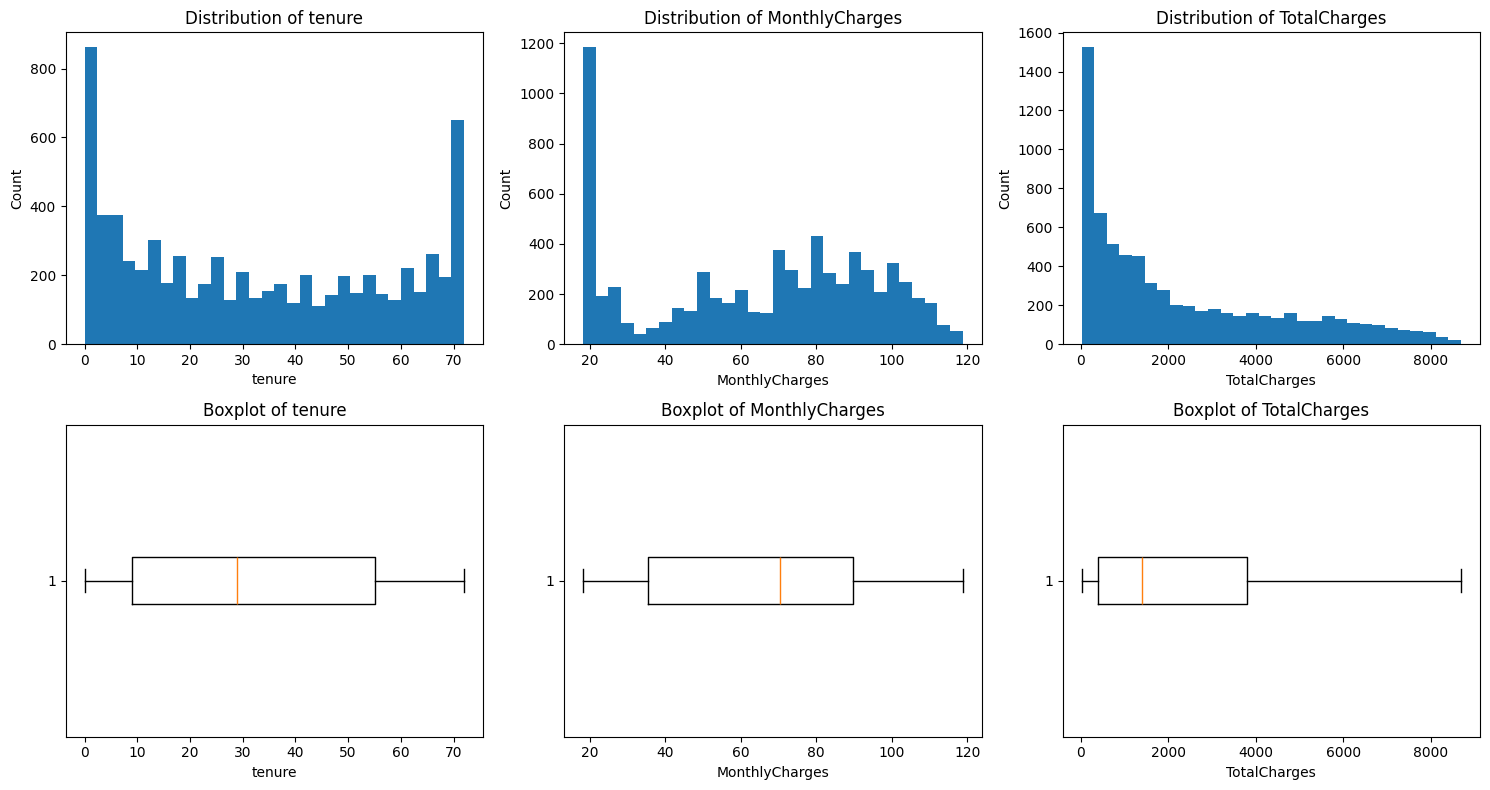

In [11]:
import matplotlib.pyplot as plt

diag = df.copy()
diag["TotalCharges"] = pd.to_numeric(diag["TotalCharges"], errors="coerce")
num = ["tenure", "MonthlyCharges", "TotalCharges"]

for col in num:
    q1, q3 = diag[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    out = ((diag[col] < q1 - 1.5*iqr) | (diag[col] > q3 + 1.5*iqr)).sum()
    print(f"{col}: skew = {diag[col].skew():.2f} | IQR outliers = {out}")

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(num):
    axes[0, i].hist(diag[col].dropna(), bins=30)
    axes[0, i].set_title(f"Distribution of {col}")
    axes[0, i].set_xlabel(col); axes[0, i].set_ylabel("Count")
    axes[1, i].boxplot(diag[col].dropna(), vert=False)
    axes[1, i].set_title(f"Boxplot of {col}"); axes[1, i].set_xlabel(col)
plt.tight_layout(); plt.show()

### Outliers and skewness
| Feature | Skew | IQR outliers |
|---|---|---|
| tenure | 0.24 | 0 |
| MonthlyCharges | -0.22 | 0 |
| TotalCharges | 0.96 | 0 |

- **No outliers** were detected by the IQR rule in any numeric feature. Extreme values (e.g., tenure = 72, TotalCharges ≈ $8,600) are realistic, so **no outlier treatment is needed**.
- **tenure** has a U-shaped distribution: peaks of brand-new customers (0–1 month) and long-term customers (72 months).
- **MonthlyCharges** is bimodal: a large cluster at ~$20 (phone-only plans) and another between $70–$100 (internet plans). Its skew is close to 0, but the distribution is clearly not normal.
- **TotalCharges** is moderately right-skewed (0.96), as expected since it accumulates over time (≈ tenure × MonthlyCharges).
- **Implication:** since these distributions are not normal, rank-based coefficients (Spearman, Kendall) will be more appropriate than Pearson in the correlation analysis. No transformation was applied because the values are real and the skew is moderate.

In [12]:
addon_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
              "TechSupport", "StreamingTV", "StreamingMovies"]

no_internet = df["InternetService"] == "No"
print("Customers without internet:", no_internet.sum())
for col in addon_cols:
    match = (df.loc[no_internet, col] == "No internet service").all()
    print(f"{col}: 'No internet service' only when InternetService = No -> {match}, count = {(df[col] == 'No internet service').sum()}")

print("\nMultipleLines 'No phone service':", (df["MultipleLines"] == "No phone service").sum(),
      "| PhoneService = No:", (df["PhoneService"] == "No").sum())

Customers without internet: 1526
OnlineSecurity: 'No internet service' only when InternetService = No -> True, count = 1526
OnlineBackup: 'No internet service' only when InternetService = No -> True, count = 1526
DeviceProtection: 'No internet service' only when InternetService = No -> True, count = 1526
TechSupport: 'No internet service' only when InternetService = No -> True, count = 1526
StreamingTV: 'No internet service' only when InternetService = No -> True, count = 1526
StreamingMovies: 'No internet service' only when InternetService = No -> True, count = 1526

MultipleLines 'No phone service': 682 | PhoneService = No: 682


### Redundant categories ("No internet service" / "No phone service")
- The 6 internet add-on columns contain "No internet service" in **exactly the 1,526 rows** where `InternetService = No`.
- `MultipleLines` contains "No phone service" in **exactly the 682 rows** where `PhoneService = No`.
- This explains most "High correlation" alerts in the profiling report: the correlation comes from how the data was encoded, not from real customer behaviour.
- **Decision:** recode these values as "No", since the information is already captured by `InternetService` and `PhoneService`.

### Summary of data quality issues
| Issue | Evidence | Action (Step 5) |
|---|---|---|
| `TotalCharges` stored as text | dtype = object; 11 blank strings | Convert to numeric, fill 11 blanks with 0 |
| `customerID` not useful | 7,043 unique values | Drop column |
| Redundant categories | 1,526 / 682 rows fully determined by another column | Recode as "No" |
| Inconsistent binary encoding | `SeniorCitizen` 0/1 vs. others Yes/No | Encode all Yes/No columns as 0/1 |
| Duplicate profiles | 22 rows (tenure = 1, basic plans) | Keep — distinct real customers |
| Outliers | 0 by IQR rule | No action |
| Skewness | TotalCharges skew = 0.96 | No transformation; use rank-based correlations |
| Target imbalance | 73.5% No / 26.5% Yes | Documented; no resampling needed for this project |

In [13]:
df_clean = df_raw.copy()
before_shape = df_clean.shape

# 1. Drop identifier
df_clean = df_clean.drop(columns="customerID")

# 2. TotalCharges: text -> numeric, 11 blanks -> 0 (tenure = 0, not billed yet)
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"].str.strip().replace("", np.nan))
n_filled = df_clean["TotalCharges"].isna().sum()
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0)

# 3. Recode redundant categories
df_clean[addon_cols] = df_clean[addon_cols].replace("No internet service", "No")
df_clean["MultipleLines"] = df_clean["MultipleLines"].replace("No phone service", "No")

# 4. Encode Yes/No columns as 1/0 (consistent with SeniorCitizen)
yes_no_cols = [c for c in df_clean.columns
               if set(df_clean[c].dropna().unique()) <= {"Yes", "No"}]
df_clean[yes_no_cols] = df_clean[yes_no_cols].replace({"Yes": 1, "No": 0}).astype(int)

# Before/after check
print("Shape before:", before_shape, "| after:", df_clean.shape)
print("TotalCharges blanks filled with 0:", n_filled)
print("TotalCharges dtype:", df_clean["TotalCharges"].dtype)
print("Encoded Yes/No columns:", yes_no_cols)
print("Missing values after cleaning:", df_clean.isna().sum().sum())
print("Remaining text columns:", df_clean.select_dtypes("object").columns.tolist())

# 5. Export
df_clean.to_csv("outputs/Dataset-Fixed.csv", index=False)

Shape before: (7043, 21) | after: (7043, 20)
TotalCharges blanks filled with 0: 11
TotalCharges dtype: float64
Encoded Yes/No columns: ['Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'Churn']
Missing values after cleaning: 0
Remaining text columns: ['gender', 'InternetService', 'Contract', 'PaymentMethod']


/tmp/ipykernel_10382/1793251706.py:19: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_clean[yes_no_cols] = df_clean[yes_no_cols].replace({"Yes": 1, "No": 0}).astype(int)


### Cleaning summary (Step 5)
| Step | Issue | Method | Why | Affected |
|---|---|---|---|---|
| 1 | `customerID` has no analytical value | Dropped column | Unique identifier, cannot explain churn | 1 column |
| 2 | `TotalCharges` stored as text with blanks | Converted to float; blanks filled with 0 | Blanks belong to customers with tenure = 0, who have not been billed yet | 11 values |
| 3 | Redundant "No internet service" / "No phone service" | Recoded as "No" | Information already captured by `InternetService` / `PhoneService` | 1,526 rows × 6 cols; 682 rows × 1 col |
| 4 | Inconsistent binary encoding | Yes/No → 1/0 in 12 columns | Consistent with `SeniorCitizen` and required for correlation with `Churn` | 12 columns |

- **Before:** 7,043 rows × 21 columns | **After:** 7,043 rows × 20 columns (no rows removed).
- 0 missing values remain. `gender`, `InternetService`, `Contract` and `PaymentMethod` stay categorical and will be analysed with a categorical association measure (Cramér's V).
- The original dataset (`df_raw`) was not modified; the cleaned version was exported as **Dataset-Fixed.csv**.

In [14]:
from scipy.stats import pearsonr, spearmanr, kendalltau, chi2_contingency

df_clean["Contract_ord"] = df_clean["Contract"].map(
    {"Month-to-month": 0, "One year": 1, "Two year": 2})

def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2, p, _, _ = chi2_contingency(table)
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1))), p

rows = []
for feat in ["tenure", "Contract_ord", "MonthlyCharges"]:
    x, y = df_clean[feat], df_clean["Churn"]
    v, v_p = cramers_v(df_clean["Contract"], y) if feat == "Contract_ord" else (np.nan, np.nan)
    rows.append({"Pair": f"{feat} vs Churn",
                 "Pearson (point-biserial)": pearsonr(x, y)[0],
                 "Spearman": spearmanr(x, y)[0],
                 "Kendall": kendalltau(x, y)[0],
                 "Cramér's V": v})
corr_table = pd.DataFrame(rows).round(3)
print(corr_table.to_string(index=False))

print("\nChurn rate by contract:")
print(df_clean.groupby("Contract")["Churn"].agg(["count", "mean"]).round(3))

                   Pair  Pearson (point-biserial)  Spearman  Kendall  Cramér's V
        tenure vs Churn                    -0.352    -0.367   -0.303         NaN
  Contract_ord vs Churn                    -0.397    -0.406   -0.387        0.41
MonthlyCharges vs Churn                     0.193     0.185    0.151         NaN

Churn rate by contract:
                count   mean
Contract                    
Month-to-month   3875  0.427
One year         1473  0.113
Two year         1695  0.028


### Correlation results (Step 7)
| Association | Pearson (point-biserial) | Spearman | Kendall | Cramér's V | Direction | Strength | Most appropriate |
|---|---|---|---|---|---|---|---|
| tenure → Churn | -0.352 | -0.367 | -0.303 | – | Negative | Weak (near moderate) | Spearman |
| Contract → Churn | -0.397 | -0.406 | -0.387 | 0.410 | Negative | Moderate | Cramér's V |
| MonthlyCharges → Churn | 0.193 | 0.185 | 0.151 | – | Positive | Very weak | Spearman |

**1. tenure → Churn:** customers who stay longer are less likely to leave. Spearman is preferred because tenure is U-shaped (not normal); the point-biserial value confirms the result.

**2. Contract → Churn (strongest association):** churn is 42.7% for month-to-month, 11.3% for one-year and 2.8% for two-year contracts — a 15× difference. Cramér's V is the most appropriate measure because Contract is categorical; since it is also ordinal, Spearman shows the direction: longer contracts, less churn.

**3. MonthlyCharges → Churn:** higher charges are only very weakly associated with churn. MonthlyCharges is bimodal, so Spearman is preferred. The weak value suggests price alone does not drive churn; the effect is likely concentrated in specific groups (e.g., fiber optic customers, who pay more and churn more).

**Notes:** Kendall values are systematically lower because it measures pair concordance on a different scale, especially with a binary variable full of ties — all three coefficients agree in direction and ranking. Correlation does not prove causation: e.g., long contracts may reduce churn, or customers who already intend to stay may choose long contracts.

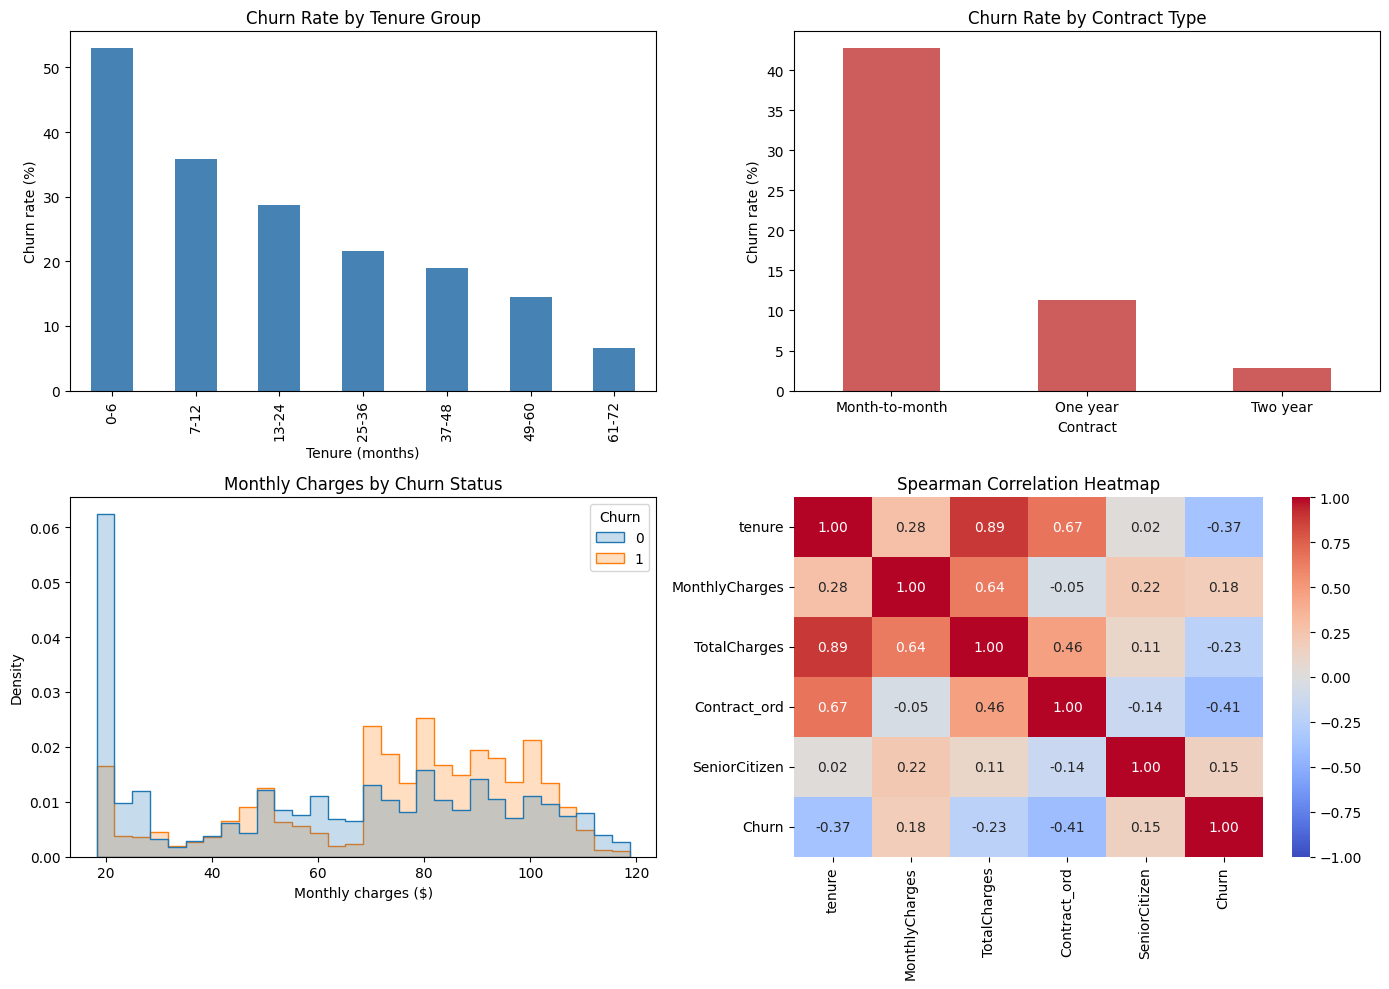

In [15]:
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Churn rate by tenure group
bins = [0, 6, 12, 24, 36, 48, 60, 72]
labels = ["0-6", "7-12", "13-24", "25-36", "37-48", "49-60", "61-72"]
tg = pd.cut(df_clean["tenure"], bins=bins, labels=labels, include_lowest=True)
(df_clean.groupby(tg, observed=True)["Churn"].mean() * 100).plot(kind="bar", ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Churn Rate by Tenure Group"); axes[0, 0].set_xlabel("Tenure (months)"); axes[0, 0].set_ylabel("Churn rate (%)")

# 2. Churn rate by contract
(df_clean.groupby("Contract")["Churn"].mean() * 100).loc[["Month-to-month", "One year", "Two year"]].plot(
    kind="bar", ax=axes[0, 1], color="indianred")
axes[0, 1].set_title("Churn Rate by Contract Type"); axes[0, 1].set_xlabel("Contract"); axes[0, 1].set_ylabel("Churn rate (%)")
axes[0, 1].tick_params(axis="x", rotation=0)

# 3. MonthlyCharges distribution by churn
sns.histplot(data=df_clean, x="MonthlyCharges", hue="Churn", bins=30, stat="density",
             common_norm=False, element="step", ax=axes[1, 0])
axes[1, 0].set_title("Monthly Charges by Churn Status"); axes[1, 0].set_xlabel("Monthly charges ($)"); axes[1, 0].set_ylabel("Density")

# 4. Spearman heatmap
hm_cols = ["tenure", "MonthlyCharges", "TotalCharges", "Contract_ord", "SeniorCitizen", "Churn"]
sns.heatmap(df_clean[hm_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, ax=axes[1, 1])
axes[1, 1].set_title("Spearman Correlation Heatmap")

plt.tight_layout(); plt.show()

### Visualizations (Step 8)
**Churn Rate by Tenure Group:** churn falls steadily from ~53% in the first 6 months to ~6.5% after 5 years. More than half of new customers leave, so the first months are the critical retention window. Although the correlation coefficient is only "weak" (Spearman -0.37), the practical effect is large — correlations with a binary target tend to be small, so group rates complement the coefficient.

**Churn Rate by Contract Type:** month-to-month customers churn at 42.7%, versus 11.3% (one year) and 2.8% (two years). Contract type is the clearest separator of churners and non-churners.

**Monthly Charges by Churn Status:** customers who stay are concentrated at ~$20 (phone-only plans), while churners are concentrated between $70 and $105 (internet plans). The relationship is not linear — it depends on price ranges — which explains the very weak correlation coefficient.

**Spearman Correlation Heatmap:**
- `tenure` and `TotalCharges` are very strongly correlated (0.89) because TotalCharges ≈ tenure × MonthlyCharges: this is redundancy, not a finding.
- `tenure` and `Contract` are strongly correlated (0.67): the two explanatory features overlap, so their effects on churn are partly shared.
- `SeniorCitizen` shows a very weak association with churn (0.15).

In [16]:
for col in ["InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "PaperlessBilling", "SeniorCitizen"]:
    print(f"\n{col}:")
    print(df_clean.groupby(col)["Churn"].agg(["count", "mean"]).round(3))


InternetService:
                 count   mean
InternetService              
DSL               2421  0.190
Fiber optic       3096  0.419
No                1526  0.074

PaymentMethod:
                           count   mean
PaymentMethod                          
Bank transfer (automatic)   1544  0.167
Credit card (automatic)     1522  0.152
Electronic check            2365  0.453
Mailed check                1612  0.191

TechSupport:
             count   mean
TechSupport              
0             4999  0.312
1             2044  0.152

OnlineSecurity:
                count   mean
OnlineSecurity              
0                5024  0.313
1                2019  0.146

PaperlessBilling:
                  count   mean
PaperlessBilling              
0                  2872  0.163
1                  4171  0.336

SeniorCitizen:
               count   mean
SeniorCitizen              
0               5901  0.236
1               1142  0.417


## Part D — Real-World Prediction Use Case

### Step 9: Target and input features
**Target feature:** `Churn` (1 = customer left, 0 = customer stayed).

**Input features** (selected based on the association analysis and churn rates by group):
| Feature | Evidence |
|---|---|
| `tenure` | Churn falls from ~53% (0–6 months) to ~6.5% (61–72 months) |
| `Contract` | 42.7% (month-to-month) vs. 2.8% (two year) — strongest association (Cramér's V = 0.41) |
| `MonthlyCharges` | Churners concentrated between $70–$105 |
| `InternetService` | Fiber optic 41.9% vs. DSL 19.0% vs. no internet 7.4% |
| `PaymentMethod` | Electronic check 45.3% vs. ~15–17% for automatic payments |
| `TechSupport`, `OnlineSecurity` | ~31% churn without the service vs. ~15% with it |
| `SeniorCitizen` | 41.7% vs. 23.6% |
| `PaperlessBilling` | 33.6% vs. 16.3% |

`TotalCharges` is **excluded** because it is redundant with `tenure` (Spearman 0.89) and `MonthlyCharges`: it adds little new information.

### Step 10: Prediction use case
**What we want to predict:** whether a customer is likely to cancel their service (churn).

**Problem type:** **Classification** — the target is binary (churn: yes / no). The model would output a churn probability for each customer, which can be used to rank customers by risk.

**Why it is useful:** acquiring a new customer typically costs more than keeping an existing one. Our analysis shows churn is highly concentrated in identifiable groups (new, month-to-month, fiber optic, electronic check customers without support services). A model can flag these customers *before* they leave, while there is still time to act.

**Who would use it and how:**
- **Retention / customer success team:** receives a monthly list of the highest-risk customers and contacts them proactively.
- **Marketing team:** designs targeted offers for high-risk customers, e.g., a discount to migrate from month-to-month to a one-year contract, a free trial of Tech Support, or an incentive to switch to automatic payment.
- **Management:** monitors expected churn and measures whether retention actions are working.

## Part E — Simulated A/B Test

### Step 11: A/B test design
**Goal:** test whether using the churn prediction model to guide retention actions improves customer retention in practice.

| | Control group | Test group |
|---|---|---|
| **Approach** | Current process: retention team works reactively (acts only when a customer asks to cancel) | Churn model flags high-risk customers each month; the retention team contacts them proactively with a retention offer (e.g., discount to switch to a one-year contract, free Tech Support trial, incentive for automatic payment) |
| **Model used** | No | Yes |

- **Assignment:** customers are randomly split into the two groups, so that the only systematic difference is the use of the model.
- **Outcome:** `retained` — 1 if the customer is still active after 3 months, 0 if they churned.
- **Outcome type:** binary (categorical), matching our classification use case.
- **Success metric:** retention rate per group.
- **Statistical test:** one-tailed two-proportion z-test, α = 0.05.

In [17]:
rng = np.random.default_rng(42)
n_per_group = 500

# Real customer profiles from the cleaned dataset, for context
profiles = df_clean.sample(2 * n_per_group, random_state=42)[["Contract", "tenure", "MonthlyCharges"]].reset_index(drop=True)

# Random assignment to groups
group = np.array(["Control"] * n_per_group + ["Test"] * n_per_group)
rng.shuffle(group)

# Simulated outcome: Control churns at the real baseline (26.5%), Test at 20% (assumed model effect)
p_retain = np.where(group == "Control", 1 - 0.265, 1 - 0.20)
retained = rng.binomial(1, p_retain)

ab_data = pd.DataFrame({
    "customer_id": range(1, 2 * n_per_group + 1),
    "group": group,
    "model_used": np.where(group == "Test", "Yes", "No"),
    "contract": profiles["Contract"],
    "tenure": profiles["tenure"],
    "monthly_charges": profiles["MonthlyCharges"],
    "retained": retained
})

ab_data.to_csv("outputs/AB_Testing_Data.csv", index=False)

print(ab_data.head(10))
print("\nCustomers per group:\n", ab_data["group"].value_counts())
print("\nRetention rate per group:\n", ab_data.groupby("group")["retained"].mean().round(3))

   customer_id    group model_used        contract  tenure  monthly_charges  \
0            1     Test        Yes  Month-to-month       1            24.80   
1            2     Test        Yes  Month-to-month      41            25.25   
2            3     Test        Yes        Two year      52            19.35   
3            4     Test        Yes  Month-to-month       1            76.35   
4            5  Control         No        Two year      67            50.55   
5            6     Test        Yes  Month-to-month      68            89.60   
6            7     Test        Yes        Two year      23            77.15   
7            8  Control         No        Two year      72            72.10   
8            9  Control         No        Two year      70           104.00   
9           10     Test        Yes  Month-to-month       1            19.40   

   retained  
0         1  
1         1  
2         0  
3         1  
4         1  
5         1  
6         0  
7         1  
8   

### Step 12: Simulated A/B testing data
- **1,000 simulated customers**, randomly assigned: 500 Control, 500 Test.
- Customer profiles (`contract`, `tenure`, `monthly_charges`) were **sampled from the real cleaned dataset** to give realistic context.
- The outcome `retained` was **simulated**: Control uses the real baseline churn rate of the dataset (26.5%); Test assumes the model reduces churn to 20%.
- Because outcomes are random draws, observed rates differ slightly from the assumed ones: **Control 70.4%, Test 78.4%** retention.
- **Why simulated:** we do not have real experimental data from a telecom company; the goal is to demonstrate how the model could be evaluated in practice.
- **Limitation:** the simulated outcome does not depend on each customer's profile (e.g., a two-year contract customer can churn as easily as a month-to-month one), which would not happen in a real experiment.
- Dataset exported as **AB_Testing_Data.csv**.

         customers  retained  retention_rate
group                                       
Control        500       352           0.704
Test           500       392           0.784

Difference (Test - Control): 8.0 percentage points
Z-statistic: 2.898
P-value: 0.0019
Decision: Reject H0


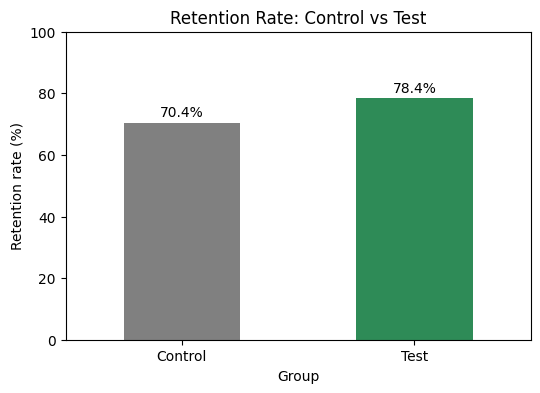

In [18]:
from statsmodels.stats.proportion import proportions_ztest

summary = ab_data.groupby("group")["retained"].agg(customers="count", retained="sum", retention_rate="mean")
print(summary.round(3))

test_s, ctrl_s = summary.loc["Test", "retained"], summary.loc["Control", "retained"]
test_n, ctrl_n = summary.loc["Test", "customers"], summary.loc["Control", "customers"]
diff = summary.loc["Test", "retention_rate"] - summary.loc["Control", "retention_rate"]
print(f"\nDifference (Test - Control): {diff*100:.1f} percentage points")

z_stat, p_value = proportions_ztest(count=[test_s, ctrl_s], nobs=[test_n, ctrl_n], alternative="larger")
print(f"Z-statistic: {z_stat:.3f}")
print(f"P-value: {p_value:.4f}")
print("Decision:", "Reject H0" if p_value <= 0.05 else "Fail to reject H0")

# Visual
(summary["retention_rate"] * 100).plot(kind="bar", color=["gray", "seagreen"], figsize=(6, 4))
plt.title("Retention Rate: Control vs Test"); plt.ylabel("Retention rate (%)"); plt.xlabel("Group")
plt.xticks(rotation=0); plt.ylim(0, 100)
for i, v in enumerate(summary["retention_rate"] * 100):
    plt.text(i, v + 2, f"{v:.1f}%", ha="center")
plt.show()

### Step 13: A/B test results
**Hypotheses** (p_c = Control retention rate, p_t = Test retention rate):
- **H0:** p_t ≤ p_c — the churn model does not improve retention.
- **H1:** p_t > p_c — the churn model improves retention.

**Test:** one-tailed two-proportion z-test, α = 0.05.

| Group | Customers | Retained | Retention rate |
|---|---|---|---|
| Control | 500 | 352 | 70.4% |
| Test | 500 | 392 | 78.4% |

- **Difference:** +8.0 percentage points in favour of the Test group.
- **Z-statistic:** 2.898 | **P-value:** 0.0019
- **Decision:** p-value ≤ 0.05 → **reject H0**.

**Interpretation:** the group where the churn model guided proactive retention actions kept significantly more customers than the group using the current process. If the model had no effect, a difference this large would occur by chance only about 0.2% of the time. In practical terms, the model-supported approach retained **40 more customers per 500**.

**Recommendation:** the result supports adopting the churn prediction model to guide retention, starting with a real pilot on a portion of the customer base. Before a full rollout, the company should confirm that the value of retained customers exceeds the cost of the retention offers, and keep